In [50]:
import jax
import optax
import jax.numpy as jnp
from jax import vmap,grad,random
from flax import struct
import numpy as np
import abc
import matplotlib.pyplot as plt
from functools import partial
import seaborn as sns
from jax.tree_util import tree_map
from sklearn.metrics import pairwise_distances
import ot
%matplotlib inline

from typing import Any, Callable, Type, Optional
from typing_extensions import TypeAlias, Self
from divergences import mmd_fixed_target, mmd_dr_embedding, KSD, KSD_dr
from kernels import gaussian_kernel, IMQ_kernel
from utils import Array, GradientFlowResult, KernelizedDivergence, Learner
from embeddings import compute_EIF_a0, compute_plugin_a0, MMD, MMD_plugin, MMD_dr
from DGPs import DGP_univariate, DGP_multimodal, DGP_high_dim_X, DGP_high_dim_M, DGP_high_dim_MX, DGP_high_dim_Y
from KRR_utils import ard_median_heuristic
from kernel_herding import kernel_herding_EIF

In [2]:
def generate_data(n,d,seed=0):
    #initial data population for MMD gradient flow
    key = jax.random.key(seed)
    x = jax.random.normal(key,(n,d))
    return x

In [8]:
def make_plots(Y_OG, Y_final, X=None, MMD=True):
    plt.figure(figsize=(8, 5))
    if Y_OG is not None:
        sns.histplot(np.array(Y_OG).ravel(), kde=True, color="red",stat="density", label="Initial Y", alpha=0.5)
    sns.histplot(np.array(Y_final).ravel(),kde=True,color="orange",stat="density",label="Final Y",alpha=0.5)
    if X is not None:
        sns.histplot(np.array(X).ravel(),kde=True,color="blue",stat="density",label="target",alpha=0.5)
    plt.xlim([X.mean()-3*X.std(),X.mean()+3*X.std()])
    plt.xlabel("Y")
    plt.ylabel("Density")
    plt.legend()
    if MMD:
        plt.title("Counterfactual Outcome Distribution via MMD gradient flow")
    else:
        plt.title("Counterfactual Outcome Distribution via minimum KSD")
    plt.tight_layout()
    plt.show()
    plt.close()

def make_joint_plots(Y_OG, Y_final, X=None, MMD=True):
    plt.figure(figsize=(8, 5))
    if Y_OG is not None:
        sns.jointplot(x=Y_OG[:,0],y=Y_OG[:,1],color="red",label="Initial Y")
    sns.jointplot(x=Y_final[:,0],y=Y_final[:,1],color="orange",label="Final Y")
    if X is not None:
        sns.jointplot(x=X[:,0],y=X[:,1],color="blue",label="target")
    plt.legend()
    if MMD:
        plt.title("Counterfactual Outcome Distribution via MMD gradient flow")
    else:
        plt.title("Counterfactual Outcome Distribution via minimum KSD")
    plt.tight_layout()
    plt.show()
    plt.close()

def evaluate_MMD(kernel_fn, ret, rate,target=None):
    #make relevant plots and calculations for MMD gradient flow results
    eval_freq = rate

    T = ret.Ys.shape[0]

    if target is not None:
        X = target
    Y = ret.Ys[0, :]

    if target is not None:
        mmd_divergence = mmd_fixed_target(kernel_fn)
        mmd_divergence.pre_compute(X)
        mmd_distance = jnp.sqrt(jax.vmap(mmd_divergence)(ret.Ys[::eval_freq, :]))

        wass_list=[]
        for i in range(T//rate):
            j=rate*i
            wass_list.append(ot.sliced_wasserstein_distance(np.array(X),np.array(ret.Ys[j,:])))
        wass_distance=jnp.array(wass_list)
        
    mmd_divergence_2 = ret.divergence
    mmd_distance_2 = jnp.sqrt(jax.vmap(mmd_divergence_2)(ret.Ys[::eval_freq, :]))    
    
    

    fig, axs = plt.subplots(1, 3, figsize=(20, 4))
    axs[0].plot(mmd_distance_2, label='mmd')
    axs[0].set_yscale('log')
    axs[0].set_xlabel('Iteration')
    axs[0].set_ylabel('MMD distance (CKME)')
    if target is not None:
        axs[1].plot(mmd_distance, label='mmd')
        axs[1].set_yscale('log')
        axs[1].set_xlabel('Iteration')
        axs[1].set_ylabel('MMD distance (truth)')
        axs[2].plot(wass_distance, label='Wasserstein')
        axs[2].set_yscale('log')
        axs[2].set_xlabel('Iteration')
        axs[2].set_ylabel('Sliced Wasserstein distance (truth)')
    plt.show()
    plt.close()
    if Y.shape[1] == 1:
        make_plots(ret.Ys[0,:,:],ret.Ys[-1,:,:],X,MMD=True)
    elif Y.shape[1] == 2:
        make_joint_plots(ret.Ys[0,:,:],ret.Ys[-1,:,:],X,MMD=True)
    if target is not None:
        print('Initial MMD (truth): ',mmd_distance[0])
        print('Final MMD (truth): ', mmd_distance[-1])
    print('Initial MMD (CKME): ',mmd_distance_2[0])
    print('Final MMD (CKME): ', mmd_distance_2[-1])    
    return

In [4]:
def gradient_flow(divergence: KernelizedDivergence, rng_key: Array, Y: Array,step_size=0.008,inject_noise_scale=100.,step_num=30000) -> GradientFlowResult:
    #MMD gradient flow
    optimizer = optax.sgd(learning_rate=step_size)
    opt_state = optimizer.init(Y)

    #to decay size of noise injection
    @jax.jit
    def scale(i):
        return jnp.sqrt(1.0 / (i + 1))

    @jax.jit
    def one_step(dummy, i: Array):
        opt_state, rng_key, Y, step_size = dummy
        optimizer = optax.sgd(learning_rate=step_size)

        first_variation = divergence.get_first_variation(Y)
        velocity_field = jax.vmap(grad(first_variation))
        u = jax.random.normal(rng_key, shape=Y.shape)
        beta = inject_noise_scale * scale(jnp.squeeze(i))
        updates, new_opt_state = optimizer.update(velocity_field(Y + beta * u), opt_state)

        Y_next = optax.apply_updates(Y, updates)

        rng_key, _ = random.split(rng_key)
        dummy_next = (new_opt_state, rng_key, Y_next, step_size)
        return dummy_next, Y_next

    info_dict, trajectory = jax.lax.scan(one_step, (opt_state, rng_key, Y, step_size), jnp.arange(step_num))


    return GradientFlowResult(divergence=divergence, Ys=trajectory)

In [51]:
n=1000
treatment=1
seed=36
dim=3

A,M,X,Y = DGP_multimodal(2*n,seed=seed,dim=dim)
A_tr=A[:n,:]
A_te=A[n:,:]
M_tr=M[:n,:]
M_te=M[n:,:]
X_tr=X[:n,:]
X_te=X[n:,:]
Y_tr=Y[:n,:]
Y_te=Y[n:,:]
A_truth,M_truth,X_truth,Y_truth = DGP_multimodal(n,seed=seed,dim=dim,gt=True,a0=treatment)



In [52]:
dr,EIF = compute_EIF_a0(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te,a0=treatment,mean=False,subsample=True)

print('DR CKME to truth: ',jnp.sqrt(MMD_dr(Y_te,Y_tr,Y_truth,EIF,dr)))

DR CKME to truth:  0.03740494


(2000, 1)
(2000, 1)
sample


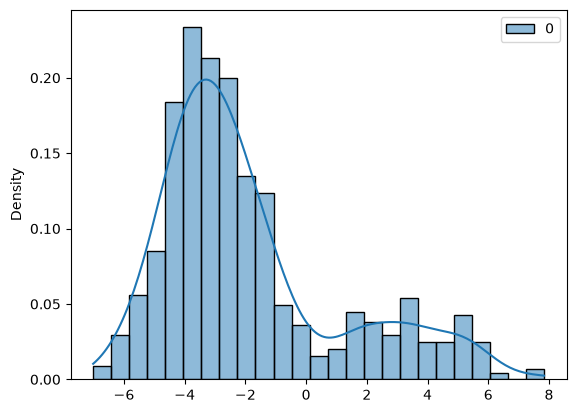

In [17]:
def conditional_sample(Y,A,treatment,n=750,key=None):
    if key is None:
        key=jax.random.key(0)

    A_indices = A == treatment
    print(Y.shape)
    print(A_indices.shape)
    Y_sample=Y[A_indices.ravel(),:]
    sample_len=Y_sample.shape[0]
    if sample_len >= n:
        perm = jax.random.permutation(key,Y_sample.shape[0])[:n]
        print('sample')
        return Y_sample[perm]
    else:
        sample=jnp.tile(Y_sample,((n//sample_len)+1))
        perm = jax.random.permutation(key,sample.shape[0])[:n]
        print('no-sample')
        return sample[perm]
    
    

bandwidth=ard_median_heuristic(Y_tr)

rng_key = jax.random.key(seed)

d=Y_tr.shape[1]
#generate initial particle population
Y=conditional_sample(jnp.concatenate((Y_tr,Y_te),axis=0),jnp.concatenate((A_tr,A_te),axis=0),treatment=treatment)
#sns.jointplot(x=Y[:,0],y=Y[:,1],color="red")
#plt.show()

sns.histplot(Y,stat='density',kde=True)
plt.show()

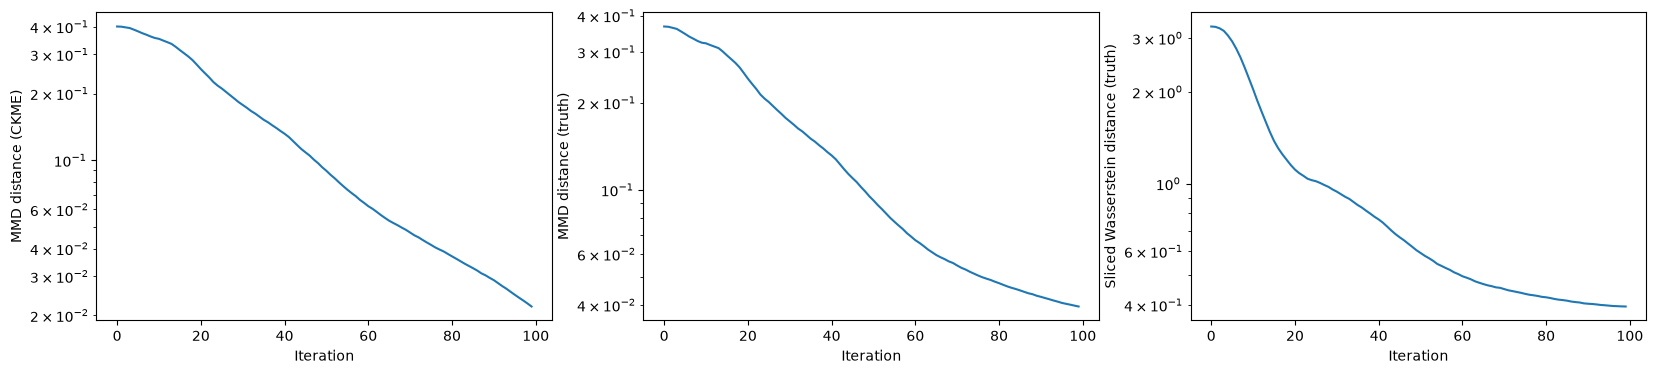

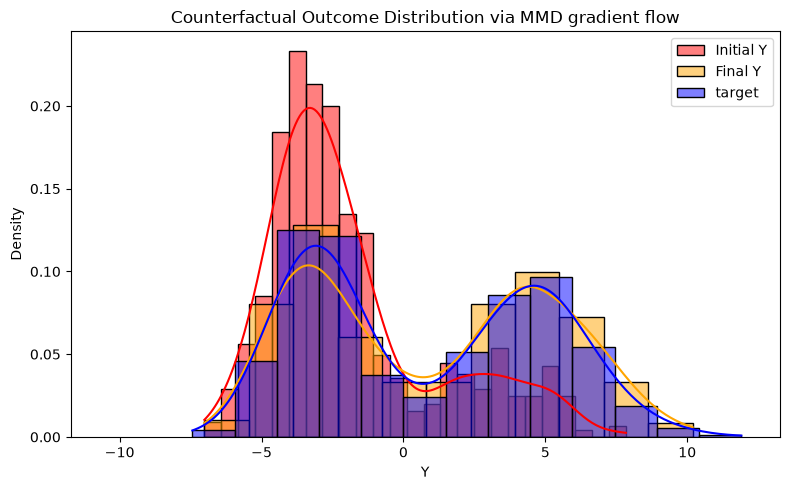

Initial MMD (truth):  0.3672448
Final MMD (truth):  0.039506298
Initial MMD (CKME):  0.40098265
Final MMD (CKME):  0.021921735


In [19]:
#set kernel for MMD
kernel=gaussian_kernel(bandwidth)

divergence = mmd_dr_embedding(kernel, dr,EIF)
divergence.pre_compute(Y_tr,Y_te)

ret = gradient_flow(divergence, rng_key, Y,step_size=0.1,inject_noise_scale=1000.,step_num=100000)
rate = 1000
evaluate_MMD(kernel, ret, rate,target=Y_truth)

In [20]:
import blackjax
import jax.scipy.stats as stats
import jax.scipy.special as sp
from functools import partial

class Gaussian_Learner(Learner):
        
    def sample(self, n, theta: Array, rng_key: Array) -> Array:
        return jnp.sqrt(jnp.exp(theta[1]))*random.normal(rng_key, shape=(n,1))+theta[0]*jnp.ones((n,1))

    def log_prob(self, theta: Array, x: Array) -> Float:
        return stats.norm.logpdf(x,loc=theta[0],scale=jnp.exp(theta[1]))

class Gaussian_Learner_only_mean(Learner):

    def sample(self, n, theta: Array, rng_key: Array) -> Array:
        return random.normal(rng_key, shape=(n,1))+theta[0]*jnp.ones((n,1))

    def log_prob(self, theta: Array, x: Array) -> Float:
        return stats.norm.logpdf(x,loc=theta[0])



class EBM_learner(Learner):
    
    def sample(self,n,params: Array, rng_key: Array) -> Array:
        
        def inference_loop(rng_key, kernel, initial_state, num_samples):
            @jax.jit
            def one_step(state, rng_key):
                state, _ = kernel(rng_key, state)
                return state, state

            keys = jax.random.split(rng_key, num_samples)
            _, states = jax.lax.scan(one_step, initial_state, keys)

            return states
        x_dim=theta.shape[0]-3
        initial_position=jnp.ones((x_dim,))
        logdensity=lambda x: self.log_prob(theta=params,x=x)
        warmup = blackjax.window_adaptation(blackjax.nuts, logdensity)
        rng_key, warmup_key, sample_key = jax.random.split(rng_key, 3)
        (state, parameters), _ = warmup.run(warmup_key, initial_position, num_steps=1000)
        kernel = blackjax.nuts(logdensity, **parameters).step
        states = inference_loop(sample_key, kernel, state, n)
        mcmc_samples = states.position
        return mcmc_samples

    def log_prob(self,theta:Array,x:Array)->Array:
        x_dim=theta.shape[0]-3
        #flat_x=x.flatten()
        h=jax.nn.swish(jnp.dot(x.T,theta[:x_dim,:])+theta[-3,:])
        p=jnp.dot(h,theta[-2,:])+theta[-1,0]
        return p
        

In [21]:
def create_parameters(rng_key, dim):
  # Returns a dictionary with the desired parameters for the network
    scale=1e-2
    params = {}
    rng_key, param_key = jax.random.split(rng_key)
    params = scale*jax.random.truncated_normal(param_key, -1, 1, (dim+3, 64))
    return params
key=jax.random.key(0)
theta=create_parameters(key,1)
k=EBM_learner()
print(k.log_prob(theta,jnp.array([2.])))
#log_prob_values=vmap(k.log_prob,(None,0))(theta,(0.1*jnp.arange(1000)-50))
#prob_values=jnp.exp(log_prob_values)
#plt.plot((0.1*jnp.arange(1000)-50),prob_values)
#plt.show()

samples=k.sample(10,theta,key)
print(samples)

0.006449094
[[-2.288357e+21]
 [-2.288357e+21]
 [-2.288357e+21]
 [-2.288357e+21]
 [-2.288357e+21]
 [-2.288357e+21]
 [-2.288357e+21]
 [-2.288357e+21]
 [-2.288357e+21]
 [-2.288357e+21]]


In [42]:
def optimise_KSD(KSD_estimate,rng_key: Array,params: Array,step_size=0.005,inject_noise_scale=100.,step_num=100000):
    #gradient descent for theta on KSD loss
    optimizer = optax.adam(learning_rate=step_size)
    opt_state = optimizer.init(params)

    @jax.jit
    def scale(i):
        return jnp.sqrt(1.0 / (i + 1))

    @jax.jit
    def one_step(dummy, i: Array):
        opt_state, rng_key, params, step_size = dummy
        optimizer = optax.adam(learning_rate=step_size)

        grads = grad(KSD_estimate.loss)(params)
        u = jax.random.normal(rng_key, shape=params.shape)
        beta = inject_noise_scale * scale(jnp.squeeze(i))
        updates, new_opt_state = optimizer.update(grads, opt_state, params)
        #updates, new_opt_state = optimizer.update(velocity_field(Y), opt_state)
        params_next = optax.apply_updates(params, updates)

        rng_key, _ = random.split(rng_key)
        dummy_next = (new_opt_state, rng_key, params_next, step_size)
        return dummy_next, params_next

    info_dict, trajectory = jax.lax.scan(one_step, (opt_state, rng_key, params, step_size), jnp.arange(step_num))

    Ys=tree_map(lambda x: x, trajectory)
    return Ys

def evaluate_KSD(KSD_estimate, thetas, rate, rng_key, sampling=False, target=None):
    # make relevant plots and do calculations for results of KSD gradient descent
    eval_freq = rate

    T = thetas.shape[0]
    x_dim=thetas.shape[1]-3

    if sampling:
        #draw samples from parametric distribution
        Ys=jax.vmap(KSD_estimate.distribution.sample, (None,0,None))(750,thetas[::eval_freq,:],rng_key)

        if target is not None:
            #MMD between samples from parametric distribution and truth
            bandwidth=ard_median_heuristic(target)
            kernel=gaussian_kernel(bandwidth)
            mmd_1 = mmd_fixed_target(kernel)
            mmd_1.pre_compute(target)
            mmd_distance = jnp.sqrt(jax.vmap(mmd_1)(Ys))

            wass_list=[]
            for i in range(Ys.shape[0]):
                wass_list.append(ot.sliced_wasserstein_distance(np.array(X),np.array(Ys[i,:])))
            wass_distance=jnp.array(wass_list)
    
        #MMD between samples from parametric distribution and debiased CKME
        X_tr = KSD_estimate.X_tr
        bandwidth=np.median(pairwise_distances(X_tr)) ** 2 + 1e-8
        kernel=gaussian_kernel(bandwidth)
        X_te = KSD_estimate.X_te
        dr=KSD_estimate.dr
        eif=KSD_estimate.eif
        mmd_2 = mmd_dr_embedding(kernel, dr,eif)
        mmd_2.pre_compute(X_tr,X_te)
        mmd_distance_2 = jnp.sqrt(jax.vmap(mmd_2)(Ys))
    
    KSD_distance = jax.vmap(KSD_estimate.loss)(thetas[::eval_freq])

    fig, axs = plt.subplots(2, 2, figsize=(14, 8))
    axs[0,0].plot(KSD_distance, label='KSD')
    axs[0,0].set_yscale('log')
    axs[0,0].set_xlabel('Iteration')
    axs[0,0].set_ylabel('KSD distance')
    if sampling:
        if target is not None:
            axs[0,1].plot(mmd_distance, label='MMD (truth)')
            axs[0,1].set_yscale('log')
            axs[0,1].set_xlabel('Iteration')
            axs[0,1].set_ylabel('MMD distance from truth')
            axs[1,0].plot(wass_distance, label='Wasserstein')
            axs[1,0].set_yscale('log')
            axs[1,0].set_xlabel('Iteration')
            axs[1,0].set_ylabel('Sliced Wasserstein distance (truth)')
        axs[1,1].plot(mmd_distance_2, label='MMD (CKME)')
        axs[1,1].set_yscale('log')
        axs[1,1].set_xlabel('Iteration')
        axs[1,1].set_ylabel('MMD distance from CKME')
    plt.show()
    plt.close()
    print('Initial KSD: ',KSD_distance[0])
    print('Final KSD: ', KSD_distance[-1])
    if sampling:
        if target is not None:
            print('Initial MMD (truth): ',mmd_distance[0])
            print('Final MMD (truth): ', mmd_distance[-1])
            #make_plots(None,Ys[-1,:,:],Y_truth,MMD=False)
            if x_dim == 1:
                make_plots(None,Ys[-1,:,:],Y_truth,MMD=False)
            elif x_dim == 2:
                make_joint_plots(None,Ys[-1,:,:],Y_truth,MMD=False)
        print('Initial MMD (CKME): ',mmd_distance_2[0])
        print('Final MMD (CKME): ', mmd_distance_2[-1])
    #print('Initial parameter: ', thetas[0])
    #print('Final parameter: ', thetas[-1])
    return

In [23]:
n=1000
treatment=1
seed=36
dim=3

A,M,X,Y = DGP_multimodal(2*n,seed=seed,dim=dim)
A_tr=A[:n,:]
A_te=A[n:,:]
M_tr=M[:n,:]
M_te=M[n:,:]
X_tr=X[:n,:]
X_te=X[n:,:]
Y_tr=Y[:n,:]
Y_te=Y[n:,:]
A_truth,M_truth,X_truth,Y_truth = DGP_multimodal(n,seed=seed,dim=dim,gt=True,a0=treatment)

dr,EIF = compute_EIF_a0(A_tr,M_tr,X_tr,Y_tr,A_te,M_te,X_te,Y_te,a0=treatment,mean=False,subsample=True)

print('DR CKME to truth: ',jnp.sqrt(MMD_dr(Y_te,Y_tr,Y_truth,EIF,dr)))

DR CKME to truth:  0.03740494


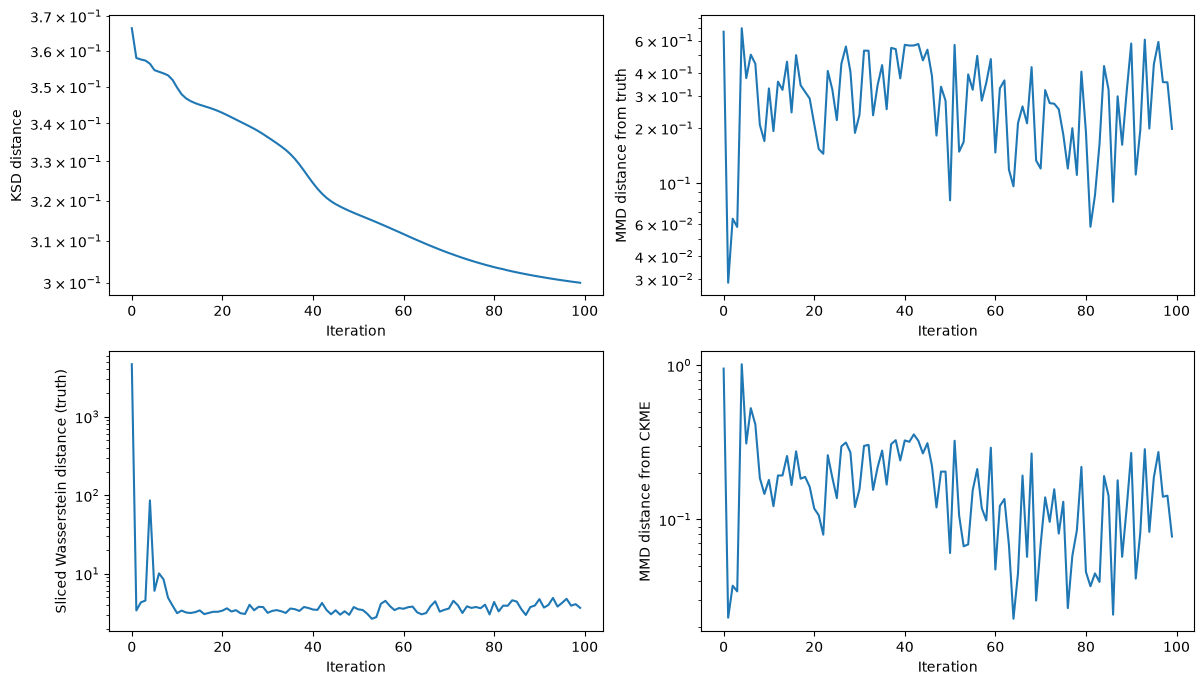

Initial KSD:  0.36646938
Final KSD:  0.2999483
Initial MMD (truth):  0.6703445
Final MMD (truth):  0.19802423


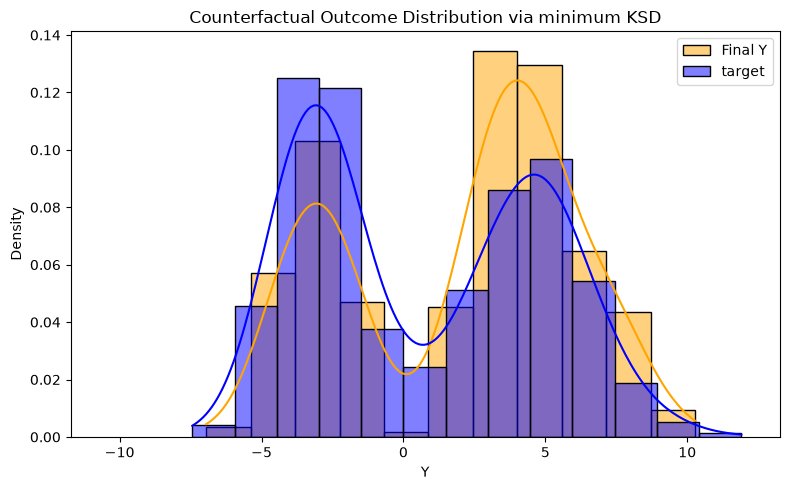

Initial MMD (CKME):  0.95047706
Final MMD (CKME):  0.07751532


In [49]:
k = EBM_learner()
rng_key = jax.random.key(0)
ksd=KSD_dr(k, IMQ_kernel(bandwidth), dr, EIF)
ksd.pre_compute(Y_tr,Y_te)
key=jax.random.key(0)
params=create_parameters(key,Y_tr.shape[1])
param_estimates=optimise_KSD(ksd,rng_key,params,step_size=0.001,inject_noise_scale=100.,step_num=100000)
evaluate_KSD(ksd, param_estimates, 1000,rng_key, True, Y_truth)